Team Setup

In [1]:
# Team Setup
team_setup = {
    'team_name': 'DS System Pros',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Jennifer Lutchen', 'github': 'https://github.com/Jennifer-Lutchen/ds2002-fa26'},
        {'name': 'Malia Heupel', 'github': 'https://github.com/maliaheupel'},
        {'name': 'Claire Zhang', 'github': 'https://github.com/legsleggylegs/ds2002-fa26'}
    ],
    'repo_url': 'https://github.com/maliaheupel/walmart/tree/main',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/maliaheupel/walmart/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Malia Heupel',           # nice to have
    'meeting_time': 'in class',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['figuring out how to work together in colab','unsure how to handle negative numbers','should we keep rows without a timestamp??','what should we do about SKUs we are uncertain about?'],              # nice to have, five specific problems
}

Load Data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
transactions = pd.read_csv("walmart_transactions.csv")
distributions = pd.read_csv("distribution_centers.csv")
catalog = pd.read_csv("product_catalog.csv")
locations = pd.read_csv('store_locations.csv')

Look at the data first before making decisions

In [3]:

# take a look at the data
print("shape (rows,columns):")
display(transactions.shape)
print("\nhead:")
display(transactions.head())
print("\nData types:")
print(transactions.dtypes)
print("\nMissing values:")
print(transactions.isnull().sum())
print("\nExact duplicates:",transactions.duplicated().sum())

# look at the specific problems
print("Negative quantities:")
display(transactions[transactions['quantity']<0].head())
print("Count:",(transactions['quantity']<0).sum())
print("\nUnit prices containing $:")
display(transactions[transactions['unit_price'].astype(str).str.contains('$',regex=False)].head())
print("Count:",transactions['unit_price'].astype(str).str.contains('$',regex=False).sum())
print("\nStore ID samples:")
print(transactions['store_id'].value_counts().head(20))

# look at the timestamp format
parsed_time = pd.to_datetime(transactions['timestamp'],errors='coerce',format='mixed')
print("Missing before parsing:",transactions['timestamp'].isna().sum())
print("Missing after parsing:", parsed_time.isna().sum())

shape (rows,columns):


(25562, 8)


head:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82



Data types:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

Missing values:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

Exact duplicates: 30
Negative quantities:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
163,TXN008747,FL-078,2024-09-22T21:30:35,PAPERTOWEL6,Paper Towels,HOUSEHOLD,-2,7.91
223,TXN006255,FL-619,2024-09-20 17:10:14,DIAPERS-3,Diapers Size 3,baby,-2,25.79
563,TXN013118,FL-330,09-25-2024 11:32:05,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,-2,19.58
811,TXN022136,FL-287,09-06-2024 13:20:05,TP-12,TP 12 Pack,household,-2,$9.64
1034,TXN018762,FL-619,2024-09-30 14:42:48,FAID-01,First-Aid Kit,Health,-2,14.45


Count: 130

Unit prices containing $:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
10,TXN022661,FL-412,2024-09-07 17:22:06,CARDS-01,PLAYING CARDS,entertainment,2,$4.76
11,TXN009801,FL-287,09-23-2024 18:24:47,CHIPVARIETY,Chips Variety Pack,SNACKS,2,$8.75
20,TXN001671,FL-445,2024-09-14T21:52:07,PNUTBTR-16,Peanut Butter,Grocery,2,$3.31
24,TXN006442,FL-710,NaN,PAPERTOWEL6,Paper Towels,Household,1,$7.82
44,TXN007968,FL105,2024-09-22 11:38:37,FLASH-01,FLASHLIGHT LED,EMERGENCY,3,$13.02


Count: 3029

Store ID samples:
store_id
FL-445    1819
FL-156    1808
FL-710    1804
FL-105    1800
FL-412    1787
FL-302    1778
FL-330    1773
FL-287    1749
FL-078    1746
FL-501    1728
FL-239    1727
FL-619    1695
FL_302     151
FL_239     140
FL_619     133
FL_287     131
FL_330     131
FL_445     130
FL_078     127
FL_412     123
Name: count, dtype: int64
Missing before parsing: 886
Missing after parsing: 886


Data Cleaning Function

In [4]:
#build a cleaning function
def clean_transactions(df):
  out = df.drop_duplicates().copy()

  # clean unit prices
  out['unit_price'] = (out['unit_price'].astype(str).str.replace('$','',regex = False).str.strip().astype(float))

  # final project decision: negative quantities are treated as data-quality errors
  out = out[out['quantity'] >= 0].copy()

  # make timestamps all the same
  out['timestamp'] = pd.to_datetime(out['timestamp'],errors='coerce',format='mixed')

  # standardize store IDs
  out['store_id'] = (out['store_id'].str.upper().str.strip().str.replace(r'[^A-Z0-9]','',regex=True).apply(lambda s: f'{s[:2]}-{s[2:]}'))

  # standardize capitalization and spacing for categories
  out['category'] = (out['category'].str.strip().str.title())

  # consolidate category labels that mean the same thing
  category_map = {
      'Alcohol': 'Alcoholic Beverages',
      'Baby': 'Baby Products',
      'Breakfast': 'Breakfast Foods',
      'Emergency': 'Emergency Supplies',
      'Games & Entertainment': 'Entertainment',
      'Grocery': 'Groceries',
      'Health': 'Health & Wellness',
      'Household': 'Household Essentials'
  }

  out['category'] = out['category'].replace(category_map)

  return out

In [5]:
cleaned = clean_transactions(transactions)

# Keep usable rows for gross demand analysis
q1 = cleaned[
    cleaned['timestamp'].notna() &
    (cleaned['quantity'] > 0)
].copy()

q1['date'] = q1['timestamp'].dt.normalize()

# Find the five categories with the most total units
top_categories = (
    q1.groupby('category')['quantity']
    .sum()
    .nlargest(5)
    .index
)

# Daily units sold for those categories
daily = (
    q1[q1['category'].isin(top_categories)]
    .groupby(['date', 'category'])['quantity']
    .sum()
    .unstack(fill_value=0)
)

landfall = pd.Timestamp('2024-09-26')

# daily sales for every category so we can rank categories by surge
daily_all = (
    q1
    .groupby(['date', 'category'])['quantity']
    .sum()
    .unstack(fill_value=0)
)

In [6]:
# find rows affected for store_id and category
clean_store = (transactions['store_id'].str.upper().str.strip().str.replace(r'[^A-Z0-9]', '', regex=True).apply(lambda s: f'{s[:2]}-{s[2:]}'))
print("\nStore IDs changed:", (transactions['store_id'] != clean_store).sum())

clean_category = (transactions['category'].str.strip().str.title())
print("Categories changed:", (transactions['category'] != clean_category).sum())

# run the function and look at the cleaned result
print("\nRows before cleaning:", len(transactions))
cleaned = clean_transactions(transactions)
print("Rows after cleaning:",len(cleaned))
print("Rows removed:", len(transactions)-len(cleaned))

print("Negative quantities remaining:", (cleaned['quantity'] < 0).sum())
print("Rows with missing timestamps retained:", cleaned['timestamp'].isna().sum())

print("\nFinal category labels:")
print(sorted(cleaned['category'].dropna().unique()))


Store IDs changed: 4348
Categories changed: 13175

Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160
Negative quantities remaining: 0
Rows with missing timestamps retained: 881

Final category labels:
['Alcoholic Beverages', 'Baby Products', 'Breakfast Foods', 'Electronics', 'Emergency Supplies', 'Entertainment', 'Groceries', 'Health & Wellness', 'Household Essentials', 'Snacks']


### **Q1 — Demand surge**

In [7]:
# Final project asks for the 7 days before landfall
surge_start_final = landfall - pd.Timedelta(days=7)

# Baseline = all days before the seven-day surge window
baseline_final = daily_all[daily_all.index < surge_start_final].mean()

# Surge = September 19 through September 25
surge_final = daily_all[(daily_all.index >= surge_start_final) & (daily_all.index < landfall)].mean()

# Calculate surge multiple and percentage increase
surge_multiple_final = surge_final / baseline_final
percent_increase_final = (surge_multiple_final - 1) * 100

# Put results into one table
q1_results = pd.DataFrame({
    'baseline_daily_units': baseline_final,
    'surge_daily_units': surge_final,
    'surge_multiple': surge_multiple_final,
    'percent_increase': percent_increase_final
})

# Rank categories by percentage increase
top5_q1 = q1_results.sort_values('percent_increase',ascending=False).head(5)

print("\nFinal Q1 results — top five categories by 7-day surge:")
display(top5_q1.round(2))

# Keep daily data for the final top five
daily_top5 = daily_all[top5_q1.index]


Final Q1 results — top five categories by 7-day surge:


,baseline_daily_units,surge_daily_units,surge_multiple,percent_increase
category,,,,
Breakfast Foods,88.00,376.86,4.28,328.25
Emergency Supplies,381.72,1006.43,2.64,163.65
Electronics,73.50,175.86,2.39,139.26
Alcoholic Beverages,64.39,138.86,2.16,115.65
Entertainment,107.11,228.57,2.13,113.40


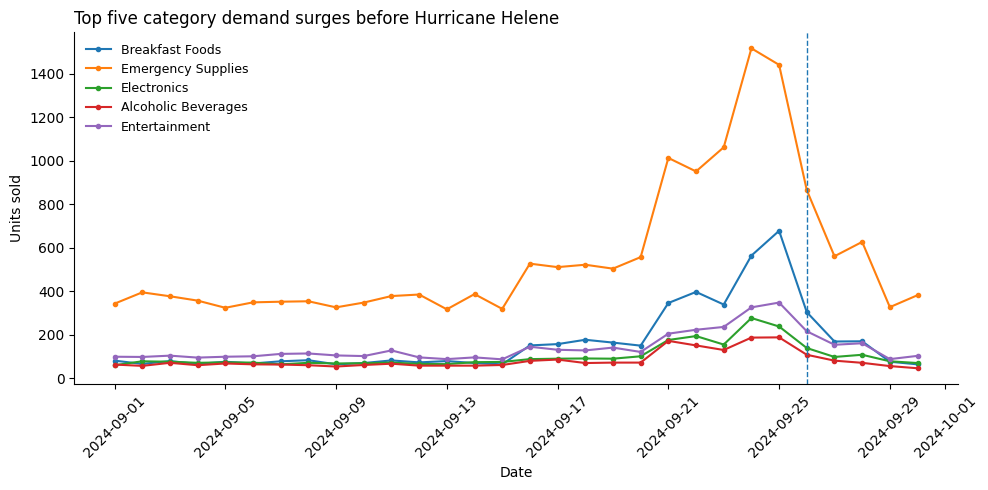

In [8]:
# Daily trend for the five categories with the largest 7-day surge
fig, ax = plt.subplots(figsize=(10, 5))

for col in daily_top5.columns:
    ax.plot(
        daily_top5.index,
        daily_top5[col],
        marker='o',
        markersize=3,
        label=col
    )

ax.axvline(landfall,linestyle='--',linewidth=1)

ax.set_title('Top five category demand surges before Hurricane Helene',loc='left',fontsize=12)

ax.set_xlabel('Date')
ax.set_ylabel('Units sold')

ax.legend(frameon=False, fontsize=9)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q1** - Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

**Answer**: During the 7-day pre-storm window (September 19-25), daily product demand spiked well above the pre-Sept 19 baseline for all five categories, led by Breakfast Foods at 4.28x normal volume followed by Emergency Supplies (2.64x), Electronics (2.39x), Alcoholic Beverages (2.16x), and Entertainment (2.13x).

### **Q2 - SKU Consolidation**

catalog shape:


(45, 7)


Distinct SKUs:
45

Product names:


,sku,product_name
0,PT-12,pop-tarts strawberry
1,SKU#459812,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry
4,WTR-24,BOTTLED WATER 24PK
5,WATER24PK,Bottled Water 24-Pack
6,WTR_24PK,Water - 24 Pack
7,BATT-100,BATTERIES AA 4PK
8,BAT-AA4,AA Batteries 4-Pack
9,BATT_AA_4PK,AA Batteries 4-Pack


,name_key,sku,product_name
12,24 beer light pack,BEER-24,Light Beer (24-pack)
13,24 beer light pack,LTBEER24,Light Beer (24-pack)
8,4 aa batteries pack,BAT-AA4,AA Batteries 4-Pack
9,4 aa batteries pack,BATT_AA_4PK,AA Batteries 4-Pack
30,aid first kit,FIRSTAID-KIT,First Aid Kit
29,aid first kit,FAID-01,First-Aid Kit
15,board game monopoly,MONOPOLY-01,Monopoly Board Game
14,board game monopoly,BG-MONO,Monopoly Board Game
16,board game monopoly,GAME-MONO,Board Game - Monopoly
24,bread white,WHITEBREAD,WHITE BREAD


Starting distinct SKUs: 45
Canonical products: 26

Largest groups:


,0
canonical_sku,
POPTART-STRAW,4
BAT-AA4,3
MONOPOLY-01,3
WTR-24,3
CANDLE-EMRG,2


,sku,product_name,canonical_sku
9,BATT_AA_4PK,AA Batteries 4-Pack,BAT-AA4
8,BAT-AA4,AA Batteries 4-Pack,BAT-AA4
7,BATT-100,BATTERIES AA 4PK,BAT-AA4
13,LTBEER24,Light Beer (24-pack),BEER-24
12,BEER-24,Light Beer (24-pack),BEER-24
24,WHITEBREAD,WHITE BREAD,BREAD-WH
23,BREAD-WH,WHITE BREAD,BREAD-WH
27,CNDL-EM,Candles (Emergency),CANDLE-EMRG
28,CANDLE-EMRG,Emergency Candles,CANDLE-EMRG
18,PLAYCARD-STD,PLAYING CARDS,CARDS-01


Units by original SKU:
sku
PT-12            1381
SKU#459812       1255
POPTART-STRAW    1300
PT_STRAWBERRY    1262
Name: quantity, dtype: int64

Consolidated Pop-Tarts units: 5198
Largest individual SKU: 1381
Consolidated total is 3.76 times the largest individual SKU


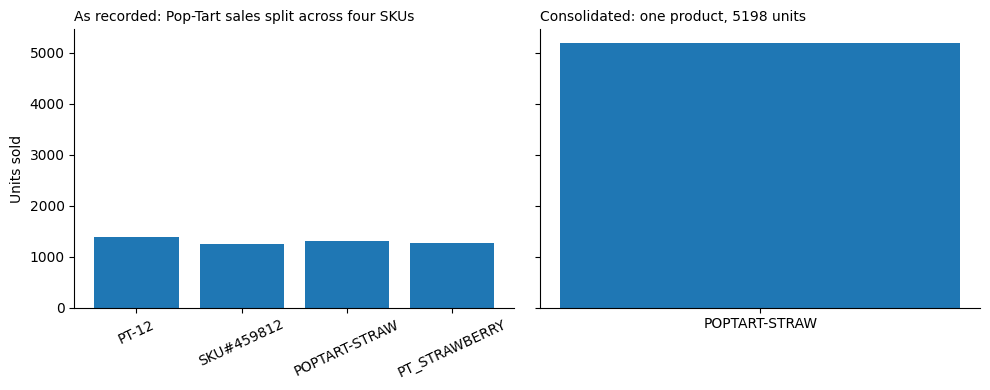


True consolidated Pop-Tart daily sales:


,POPTART-STRAW_units
date,
2024-09-01,81
2024-09-02,66
2024-09-03,79
2024-09-04,66
2024-09-05,76
2024-09-06,68
2024-09-07,78
2024-09-08,83
2024-09-09,64


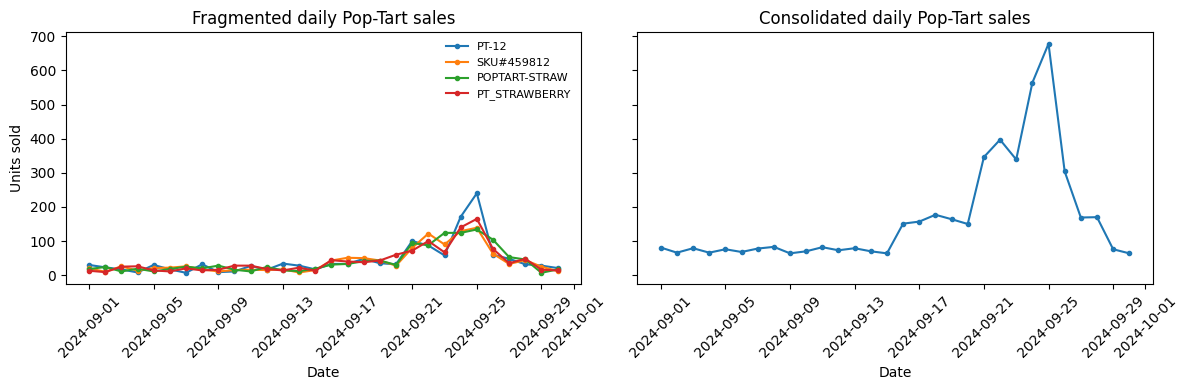

In [9]:
# inspect the dataset
print("catalog shape:")
display(catalog.shape)
print('\nDistinct SKUs:')
print(catalog['sku'].nunique())

print('\nProduct names:')
display(catalog[['sku','product_name']])

# first standardize all names to get a sense of which names mean the same thing
candidates = catalog.copy()
candidates['name_key'] = (candidates['product_name'].str.lower().str.replace(r'[^a-z0-9\s]',' ',regex=True).str.split().apply(lambda words: ' '.join(sorted(words))))
fragmented = candidates.groupby('name_key').filter(lambda group: group['sku'].nunique() >1)
display(fragmented[['name_key','sku','product_name']].sort_values('name_key'))

# combine same products with different SKUs by mapping
CANON = {
    # poptarts
    'PT-12':'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'POPTART-STRAW': 'POPTART-STRAW',
    'PT_STRAWBERRY':'POPTART-STRAW',

    # water
    'WTR-24': 'WTR-24',
    'WATER24PK':'WTR-24',
    'WTR_24PK': 'WTR-24',

    # batteries
    'BATT-100': 'BAT-AA4',
    'BAT-AA4': 'BAT-AA4',
    'BATT_AA_4PK': 'BAT-AA4',

    # flashlight
    'FLASH-01':'FLASH-01',
    'LED-FLASH':'FLASH-01',

    # beer
    'BEER-24':'BEER-24',
    'LTBEER24': 'BEER-24',

    # monopoly
    'BG-MONO':'MONOPOLY-01',
    'MONOPOLY-01':'MONOPOLY-01',
    'GAME-MONO':'MONOPOLY-01',

    # cards
    'CARDS-01':'CARDS-01',
    'PLAYCARD-STD':'CARDS-01',

    # canned soup
    'SOUP-CAN':'SOUP-CAN',
    'CNSOUP-01':'SOUP-CAN',

    # white bread
    'BREAD-WH':'BREAD-WH',
    'WHITEBREAD':'BREAD-WH',

    # peanut butter
    'PB-16':'PB-16',
    'PNUTBTR-16':'PB-16',

    # Emergency candles
    'CNDL-EM':'CANDLE-EMRG',
    'CANDLE-EMRG':'CANDLE-EMRG',

    # first aid kit
    'FAID-01':'FIRSTAID-KIT',
    'FIRSTAID-KIT':'FIRSTAID-KIT',

    # Paper towels
    'PTOWEL-6':'PTOWEL-6',
    'PAPERTOWEL6':'PTOWEL-6',

    # heavy duty tarp
    'TARP-HD':'TARP-HD',
    'HDTARP-01':'TARP-HD'
}

# apply it
catalog_clean = catalog.copy()
catalog_clean['canonical_sku'] = (catalog_clean['sku'].map(CANON).fillna(catalog_clean['sku']))

# check results
print("Starting distinct SKUs:", catalog['sku'].nunique())
print("Canonical products:", catalog_clean['canonical_sku'].nunique())

group_sizes = (catalog_clean.groupby('canonical_sku').size().sort_values(ascending=False))
print("\nLargest groups:")
display(group_sizes.head())

# show mapping
display(catalog_clean[catalog_clean['sku'].isin(CANON)][['sku','product_name','canonical_sku']].sort_values('canonical_sku'))


# Largest consolidated family: Strawberry Pop-Tarts
poptart_skus = [
    'PT-12',
    'SKU#459812',
    'POPTART-STRAW',
    'PT_STRAWBERRY'
]

# Total positive units sold under each separate SKU
fragmented = (
    cleaned[
        cleaned['sku'].isin(poptart_skus) &
        (cleaned['quantity'] > 0)
    ]
    .groupby('sku')['quantity']
    .sum()
    .reindex(poptart_skus)
    .fillna(0)
)

# Total after treating all four SKUs as one product
consolidated_units = fragmented.sum()

# Compare consolidated total with the largest individual SKU
largest_single_sku = fragmented.max()
multiple = consolidated_units / largest_single_sku

print("Units by original SKU:")
print(fragmented)

print("\nConsolidated Pop-Tarts units:", consolidated_units)
print("Largest individual SKU:", largest_single_sku)
print("Consolidated total is", round(multiple, 2), "times the largest individual SKU")

# Before-and-after chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].bar(fragmented.index,fragmented.values)

axes[0].set_title('As recorded: Pop-Tart sales split across four SKUs',fontsize=10,loc='left')

axes[0].tick_params(axis='x',labelrotation=25)

axes[1].bar(['POPTART-STRAW'],[consolidated_units])

axes[1].set_title(f'Consolidated: one product, {int(consolidated_units)} units',fontsize=10,loc='left')

axes[0].set_ylabel('Units sold')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Assertion proving consolidation did not change unit totals
consolidated = cleaned.copy()
consolidated['canonical_sku'] = (consolidated['sku'].map(CANON).fillna(consolidated['sku']))
before_total = cleaned['quantity'].sum()
after_total = consolidated['quantity'].sum()
assert before_total == after_total

# Build daily Pop-Tart sales so we can compare fragmented vs consolidated demand
poptart_daily = cleaned[cleaned['sku'].isin(poptart_skus) & cleaned['timestamp'].notna() &(cleaned['quantity'] > 0)].copy()

poptart_daily['date'] = poptart_daily['timestamp'].dt.normalize()

# Daily sales under each separate SKU
fragmented_daily = (poptart_daily.groupby(['date', 'sku'])['quantity'].sum().unstack(fill_value=0).reindex(columns=poptart_skus, fill_value=0))

# True daily Pop-Tart sales after consolidation
consolidated_daily = fragmented_daily.sum(axis=1)

print("\nTrue consolidated Pop-Tart daily sales:")
display(consolidated_daily.to_frame(name='POPTART-STRAW_units'))

# Daily before-and-after view
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for col in fragmented_daily.columns:
    axes[0].plot(
        fragmented_daily.index,
        fragmented_daily[col],
        marker='o',
        markersize=3,
        label=col
    )

axes[0].set_title('Fragmented daily Pop-Tart sales')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units sold')
axes[0].legend(frameon=False, fontsize=8)
axes[0].tick_params(axis='x', labelrotation=45)

axes[1].plot(consolidated_daily.index,consolidated_daily.values,marker='o',markersize=3)

axes[1].set_title('Consolidated daily Pop-Tart sales')
axes[1].set_xlabel('Date')
axes[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

**Q2** - After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

**Answer:** The initial 45 SKUs were reduced to 26 canonical products, which revealed that the true product-demand was severely understated, led by Strawberry Pop-Tarts (POPTART-STRAW) whose consolidated volume of 5,198 units was 3.76x larger than its single highest SKU entry while conserving total transaction units. The fragmented view could cause Walmart to underestimate demand and understock the product, while the consolidated view better supports inventory and replenishment decisions.

### **Q3 - Weather Correlation**

,date,quantity,transaction_id,store_id,timestamp,sku,product_name,category,unit_price,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,1060,"[TXN019193, TXN019010, TXN018991, TXN019141, T...","[FL-156, FL-330, FL-105, FL-287, FL-156, FL-10...","[2024-09-01 09:23:37, 2024-09-01 07:12:03, 202...","[CHIPS-VP, LED-FLASH, PTOWEL-6, TOILETPAPER12,...","[Chips Variety Pack, LED Flashlight, Paper Tow...","[Snacks, Emergency Supplies, Household Essenti...","[8.65, 12.62, 8.14, 9.67, 6.61, 30.06, 9.53, 3...",3.0,18.8,open-meteo
1,2024-09-02,1168,"[TXN020051, TXN019518, TXN020055, TXN020077, T...","[FL-710, FL-239, FL-710, FL-710, FL-105, FL-30...","[2024-09-02 18:31:07, 2024-09-02 14:45:28, 202...","[PT-12, PORTCHARGER, WTR-24, BREAD-WH, PLAYCAR...","[Pop-Tarts Strawberry, Phone Charger - Portabl...","[Breakfast Foods, Electronics, Emergency Suppl...","[3.38, 25.28, 4.8, 2.55, 4.96, 2.45, 24.78, 2....",12.4,13.5,open-meteo
2,2024-09-03,1162,"[TXN020458, TXN020304, TXN020603, TXN020348, T...","[FL-078, FL-412, FL-302, FL-156, FL-445, FL-15...","[2024-09-03 18:40:54, 2024-09-03 21:13:24, 202...","[ROKU-STD, TARP-HD, WTR-24, PT-12, CNSOUP-01, ...","[Streaming Device, TARP - HEAVY DUTY, Bottled ...","[Electronics, Emergency Supplies, Emergency Su...","[29.1, 20.8, 5.12, 3.41, 2.0, 19.27, 3.44, 8.5...",24.9,22.8,open-meteo
3,2024-09-04,1115,"[TXN020957, TXN020753, TXN020829, TXN021046, T...","[FL-156, FL-239, FL-330, FL-501, FL-501, FL-41...","[2024-09-04 07:59:12, 2024-09-04 19:42:02, 202...","[WATER24PK, TARP-HD, PB-16, CHRG-PORT, PLAYCAR...","[Bottled Water 24-Pack, HD Tarp, PEANUT BUTTER...","[Emergency Supplies, Emergency Supplies, Groce...","[5.04, 20.75, 3.13, 24.14, 4.78, 24.72, 25.38,...",22.1,15.5,open-meteo
4,2024-09-05,1076,"[TXN021859, TXN021715, TXN021381, TXN021435, T...","[FL-710, FL-619, FL-105, FL-330, FL-501, FL-41...","[2024-09-05 18:08:00, 2024-09-05 13:13:40, 202...","[SOUP-CAN, PLAYCARD-STD, WHITEBREAD, PNUTBTR-1...","[Soup - Canned, Playing Cards, White Bread, PE...","[Groceries, Entertainment, Groceries, Grocerie...","[2.04, 5.23, 2.51, 3.24, 3.24, 25.19, 25.7, 20...",23.1,15.2,open-meteo


number of rows without dates: 1
merged by date rows: 31    weather rows: 30
no days were lost
correlation is computed over 30 days


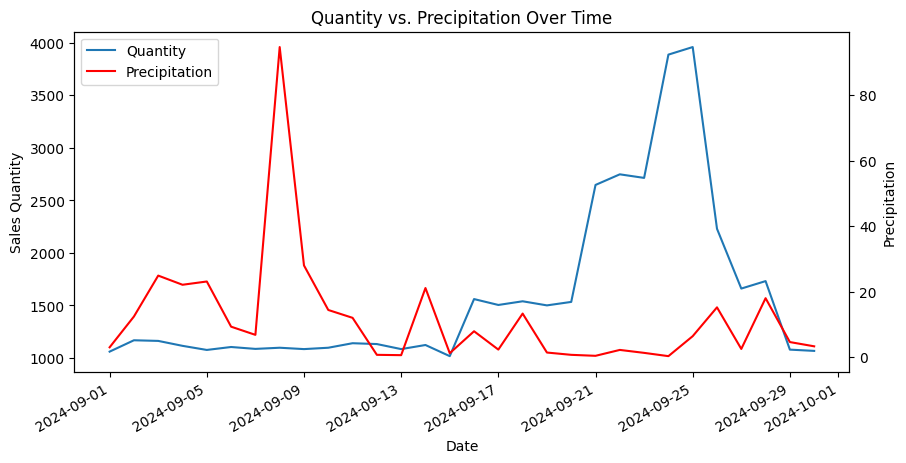

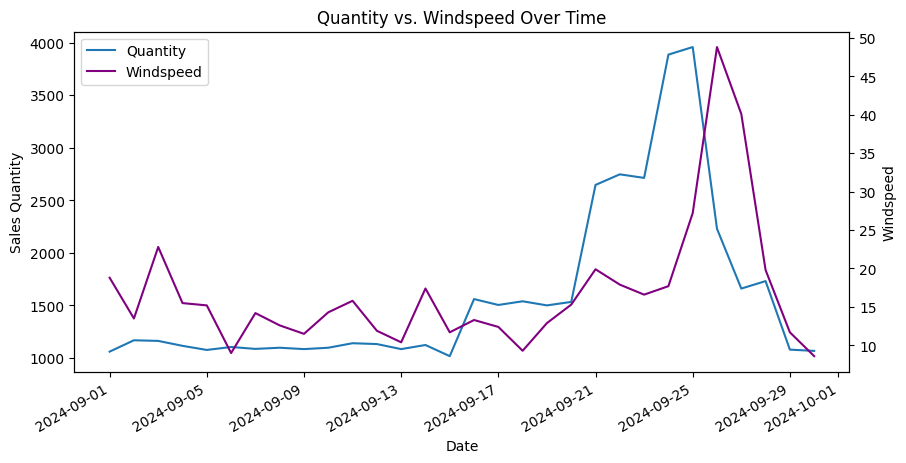


Weather data used for final analysis:


,date,precipitation_sum,windspeed_10m_max,source,pressure_msl_mean
0,2024-09-01,3.0,18.8,open-meteo,1014.1
1,2024-09-02,12.4,13.5,open-meteo,1014.1
2,2024-09-03,24.9,22.8,open-meteo,1015.7
3,2024-09-04,22.1,15.5,open-meteo,1017.8
4,2024-09-05,23.1,15.2,open-meteo,1017.3


Transaction rows before weather join: 25402
Transaction rows after weather join: 25402

Weather correlation by category:


weather_indicator,precipitation_sum,pressure_msl_mean,windspeed_10m_max
category,,,
Alcoholic Beverages,-0.256,-0.201,0.374
Baby Products,-0.361,-0.174,0.234
Breakfast Foods,-0.242,-0.279,0.407
Electronics,-0.245,-0.221,0.357
Emergency Supplies,-0.258,-0.279,0.406
Entertainment,-0.201,-0.306,0.452
Groceries,-0.288,-0.183,0.320
Health & Wellness,-0.233,-0.272,0.376
Household Essentials,-0.234,-0.248,0.395



Lag correlations:


,weather_indicator,lag_days,correlation
0,precipitation_sum,-3,-0.158
1,precipitation_sum,-2,-0.202
2,precipitation_sum,-1,-0.217
3,precipitation_sum,0,-0.256
4,precipitation_sum,1,-0.350
5,precipitation_sum,2,-0.332
6,precipitation_sum,3,-0.309
7,windspeed_10m_max,-3,0.677
8,windspeed_10m_max,-2,0.816
9,windspeed_10m_max,-1,0.707



Strongest lag for each weather indicator:


,weather_indicator,lag_days,correlation,absolute_correlation
8,windspeed_10m_max,-2,0.816,0.816
15,pressure_msl_mean,-2,-0.693,0.693
4,precipitation_sum,1,-0.350,0.350


In [10]:
from numpy import isfinite
import requests
import time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()

            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()

        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'

        return frame

weather = daily_weather(
    '2024-09-01',
    '2024-09-30'
)

cleaned["date"] = pd.to_datetime(cleaned["timestamp"].dt.date)  #creating a date-only of datetime type
merged = pd.merge(cleaned, weather, on="date", how="left") #merginging weather and cleaned on date column
merged = merged.sort_values(by='date')

#display(merged.head())
#print("number of rows without dates:",len(merged[merged['precipitation_sum'].isna()]))
#print("merged rows:", len(merged), "   sales data rows:", len(cleaned))
#assert len(merged)==len(cleaned)
#print("no days were lost")

merged_by_date = merged.groupby('date')['quantity'].sum()

#aggregating the merged rows by date, keeping arguments for other columns in lists if applicable
merged_by_date = merged.groupby('date',dropna=False).agg({
    'quantity': 'sum','transaction_id': list,'store_id': list,'timestamp': list,'sku': list,'product_name': list,'category': list,'unit_price': list,
    'precipitation_sum': 'first', 'windspeed_10m_max': 'first', 'source': 'first'
}).reset_index()
display(merged_by_date.head())
print("number of rows without dates:",len(merged_by_date[merged_by_date['date'].isna()]))
print("merged by date rows:", len(merged_by_date), "   weather rows:", len(weather))
assert len(merged_by_date) >= len(weather)
print("no days were lost")
print("correlation is computed over", len(merged_by_date[merged_by_date['date'].notna()]),"days")

#plotting correlation for precipitation_sum
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(merged_by_date['date'], merged_by_date['quantity'],label="Quantity")
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales Quantity')
ax2 = ax1.twinx()
ax2.plot(merged_by_date['date'], merged_by_date['precipitation_sum'], color='red', label='Precipitation')
ax2.set_ylabel('Precipitation')
plt.title('Quantity vs. Precipitation Over Time')
ax1.legend([ax1.lines[0], ax2.lines[0]],['Quantity', 'Precipitation'],loc='upper left')
fig.autofmt_xdate()
plt.show()

#plotting correlation for windspeed_10m_max
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(merged_by_date['date'], merged_by_date['quantity'],label="Quantity")
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales Quantity')
ax2 = ax1.twinx()
ax2.plot(merged_by_date['date'], merged_by_date['windspeed_10m_max'], color='purple', label='Windspeed')
ax2.set_ylabel('Windspeed')
plt.title('Quantity vs. Windspeed Over Time')
ax1.legend([ax1.lines[0], ax2.lines[0]],['Quantity', 'Windspeed'],loc='upper left')
fig.autofmt_xdate()
plt.show()

#no column for barometric pressure?
#plots omit the row without a date

# Pull daily mean barometric pressure from the same Open-Meteo API
pressure_params = {
    'latitude': 28.54,
    'longitude': -81.38,
    'start_date': '2024-09-01',
    'end_date': '2024-09-30',
    'daily': 'pressure_msl_mean',
    'timezone': 'America/New_York'
}

pressure_response = requests.get(BASE,params=pressure_params,timeout=10)

pressure_response.raise_for_status()

pressure = pd.DataFrame(pressure_response.json()['daily'])

pressure = pressure.rename(columns={'time': 'date'})

pressure['date'] = pd.to_datetime(pressure['date'])

# Combine pressure with the weather data we already pulled
weather_final = weather.merge(pressure,on='date',how='left')

print("\nWeather data used for final analysis:")
display(weather_final.head())


# Validate that adding weather does not remove transaction rows
merged_final = pd.merge(cleaned,weather_final,on='date',how='left')

assert len(merged_final) == len(cleaned)

print("Transaction rows before weather join:",len(cleaned))

print("Transaction rows after weather join:",len(merged_final))


# Daily sales by category
category_daily = (q1.groupby(['date', 'category'])['quantity'].sum().reset_index())

category_weather = category_daily.merge(weather_final,on='date',how='inner')

weather_columns = [
    'precipitation_sum',
    'windspeed_10m_max',
    'pressure_msl_mean'
]

# Calculate correlation between each weather indicator and each category
correlation_rows = []

for category, group in category_weather.groupby('category'):
    for weather_column in weather_columns:
        correlation_rows.append({
            'category': category,
            'weather_indicator': weather_column,
            'correlation': group['quantity'].corr(
                group[weather_column]
            )
        })

correlation_table = pd.DataFrame(correlation_rows)

print("\nWeather correlation by category:")
display(correlation_table.pivot(index='category',columns='weather_indicator',values='correlation').round(3))


# Lag analysis using total daily sales
total_daily_weather = (
    q1
    .groupby('date')['quantity']
    .sum()
    .reset_index()
    .merge(
        weather_final,
        on='date',
        how='inner'
    )
)

lag_results = []

for weather_column in weather_columns:
    for lag in range(-3, 4):
        lag_results.append({
            'weather_indicator': weather_column,
            'lag_days': lag,
            'correlation': total_daily_weather['quantity'].corr(
                total_daily_weather[weather_column].shift(lag)
            )
        })

lag_results = pd.DataFrame(
    lag_results
)

print("\nLag correlations:")
display(lag_results.round(3))

# Positive lag means the weather indicator occurred before the sales day
best_lags = (
    lag_results.assign(absolute_correlation=lambda x:x['correlation'].abs()
    )
    .sort_values('absolute_correlation',ascending=False
    )
    .groupby('weather_indicator').head(1)
)

print("\nStrongest lag for each weather indicator:")
display(best_lags.round(3))

**Q3** - Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

**Answer**: We can see from the graphs and correlation analysis that there is a lag between the spike in daily sales volume and different weather indicators. In fact, we can see purchasing volume increases before the strongest wind speed and barometric pressure relationships, with sales leading both indicators by 2 days (r = 0.816 for wind speed and r = -0.693 for pressure), while precipitation had a weaker strongest correlation at a 1-day lag (r = -0.350). This may be consistent with the idea that purchasing volume is at its peak just before a hurricane lands, as customers may increase purchases before the most severe weather arrives.

### **Q4 - Store Level Geographic Patterns**

In [11]:
# separate baseline (Sept 1-18) and surge (Sept 19-25)
baseline_data = cleaned[cleaned['date'] < '2024-09-19']
surge_data = cleaned[(cleaned['date'] >= '2024-09-19') & (cleaned['date'] < '2024-09-26')]

# calculate daily averages per store
store_baseline = baseline_data.groupby('store_id')['quantity'].sum() / 18
store_surge = surge_data.groupby('store_id')['quantity'].sum() / 7

# calculate multiplier & convert to DataFrame so 'store_id' is a column
store_multipliers = (store_surge / store_baseline).round(2).sort_values(ascending=False)
store_df = store_multipliers.reset_index()
store_df.columns = ['store_id', 'surge_multiplier']

# merge with locations metadata
merged_stores = pd.merge(store_df, locations, on='store_id', how='left')
display(merged_stores[['store_id', 'city', 'region', 'surge_multiplier']])

# outlier identification
threshold = store_multipliers.mean() + (2 * store_multipliers.std())
outliers = store_multipliers[store_multipliers > threshold]


,store_id,city,region,surge_multiplier
0,FL-330,Miami,South,2.44
1,FL-619,Tallahassee,Panhandle,2.38
2,FL-105,Tampa,West,2.37
3,FL-302,Lakeland,Central,2.34
4,FL-412,Jacksonville,North,2.33
5,FL-710,Pensacola,Panhandle,2.32
6,FL-156,Daytona Beach,East,2.32
7,FL-445,St. Petersburg,West,2.29
8,FL-287,Kissimmee,Central,2.27
9,FL-501,Fort Myers,West,2.27


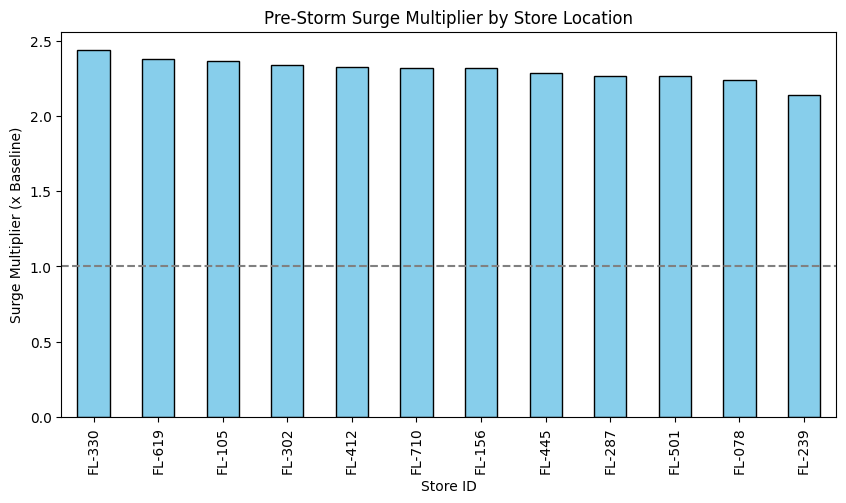

In [12]:
plt.figure(figsize=(10, 5))

store_multipliers.plot(kind='bar',color='skyblue',edgecolor='black')

plt.title('Pre-Storm Surge Multiplier by Store Location')
plt.xlabel('Store ID')
plt.ylabel('Surge Multiplier (x Baseline)')
plt.axhline(1.0, color='gray', linestyle='--')

plt.show()

**Q4** - Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

**Answer**: While all Florida locations experienced an increase in purchases before the storm, the size of the demand spike varied across stores. Store FL-330 had the highest surge multiplier at 2.44x, but no stores were identified as outliers using the calculated outlier threshold. The current analysis does not directly measure distance from Hurricane Helene’s predicted path or the timing of each store’s spike.

### **Q5 - Signal vs. Artifact - The Board Games Investigation**

In [13]:
import sqlite3

conn = sqlite3.connect('walmart_transactions.sqlite')

# load the cleaned dataframe into the SQLite transactions table
cleaned.to_sql('transactions', conn, if_exists='replace', index=False)

def q(sql):
    return pd.read_sql_query(sql, conn)

# aggregates daily quantities for games
q("""
SELECT product_name, category, SUBSTR(date, 1, 10) as tx_date, SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY product_name, tx_date
ORDER BY total_qty DESC
""")

# Connect to the supplied inventory and sales database
inventory_conn = sqlite3.connect('inventory_and_sales.db')

# Show the database tables
db_tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    """,
    inventory_conn
)

print("\nTables in supplied database:")
display(db_tables)

# Load the two supplied tables
daily_sales_db = pd.read_sql_query(
    """
    SELECT *
    FROM daily_sales_summary
    """,
    inventory_conn
)

inventory_db = pd.read_sql_query(
    """
    SELECT *
    FROM inventory_levels
    """,
    inventory_conn
)

print("\nDaily sales table:")
display(daily_sales_db.head())

print("\nInventory table:")
display(inventory_db.head())

print("\nDaily sales columns:")
print(daily_sales_db.columns.tolist())

print("\nInventory columns:")
print(inventory_db.columns.tolist())


Tables in supplied database:


,name
0,daily_sales_summary
1,inventory_levels



Daily sales table:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30



Inventory table:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35



Daily sales columns:
['date', 'store_id', 'category', 'total_units', 'total_revenue']

Inventory columns:
['date', 'store_id', 'sku', 'units_on_hand', 'units_on_order', 'reorder_point']


,standardized_product,tx_date,total_qty
0,Playing Cards,2024-09-30,53
1,Monopoly,2024-09-30,50
2,Monopoly,2024-09-29,48
3,Playing Cards,2024-09-29,40
4,Playing Cards,2024-09-28,97
...,...,...,...
57,Monopoly,2024-09-02,46
58,Playing Cards,2024-09-01,54
59,Monopoly,2024-09-01,45
60,Monopoly,None,79


Entertainment baseline daily sales: 606.25
Entertainment surge daily sales: 1394.5
Entertainment percent increase: 130.02 %

Entertainment SKU audit:


,sku,product_name,category
76,MONOPOLY-01,Board Game - Monopoly,Entertainment
171,GAME-MONO,Board Game - Monopoly,Entertainment
429,BG-MONO,Board Game - Monopoly,Entertainment
292,MONOPOLY-01,MONOPOLY,Entertainment
385,BG-MONO,MONOPOLY,Entertainment
612,GAME-MONO,MONOPOLY,Entertainment
65,BG-MONO,Monopoly Board Game,Entertainment
125,MONOPOLY-01,Monopoly Board Game,Entertainment
157,GAME-MONO,Monopoly Board Game,Entertainment
10,CARDS-01,PLAYING CARDS,Entertainment



Board-game inventory baseline: 1332.78
Board-game inventory during surge: 1009.86
Inventory percent change: -24.23 %


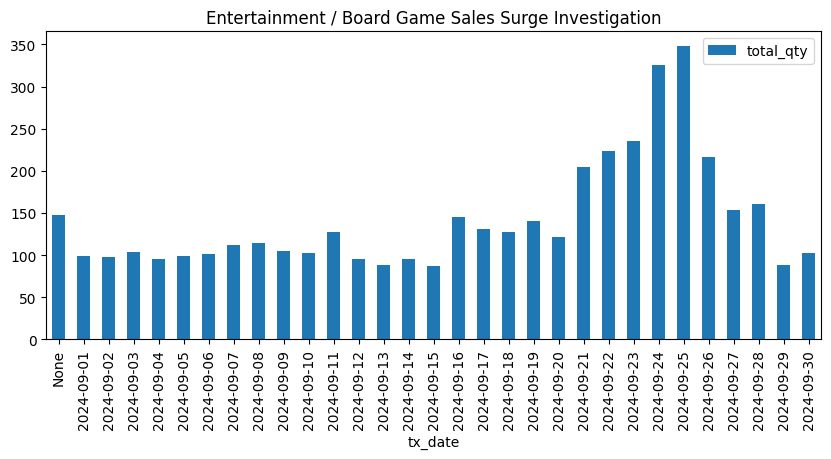

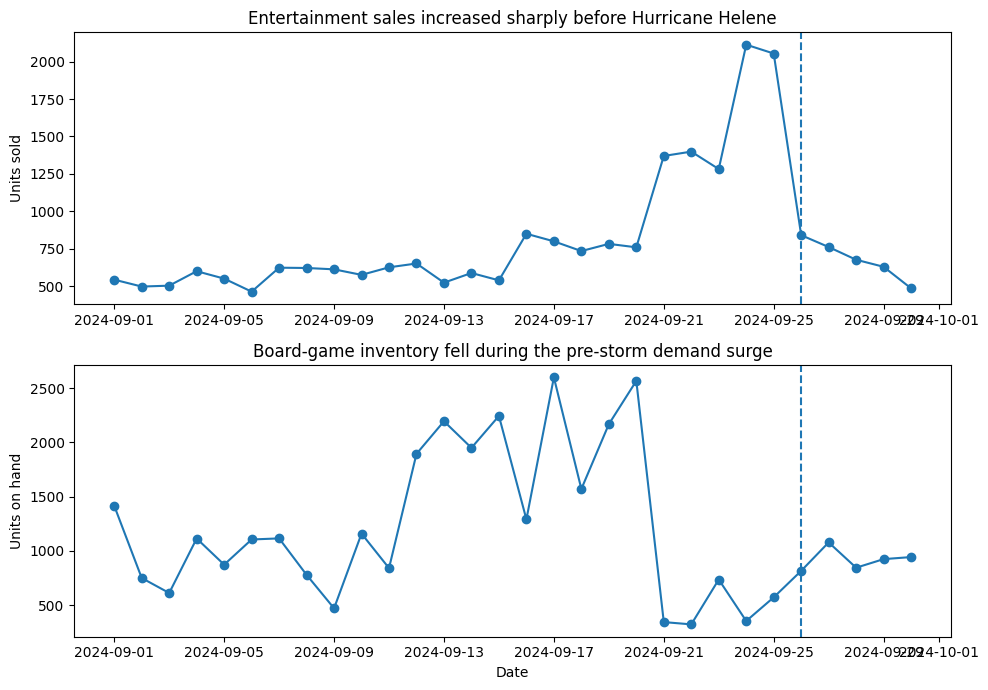

In [14]:
# consolidates data into one product name
product_chart = q("""
SELECT
    CASE
        WHEN LOWER(product_name) LIKE '%monopoly%' THEN 'Monopoly'
        WHEN LOWER(product_name) LIKE '%playing card%' THEN 'Playing Cards'
        ELSE product_name
    END as standardized_product,
    SUBSTR(date, 1, 10) as tx_date,
    SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY standardized_product, tx_date
ORDER BY tx_date DESC, total_qty DESC
""")

display(product_chart)

# entertainment/game sales volume over time
chart_df = q("""
SELECT SUBSTR(date, 1, 10) as tx_date, SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY tx_date
ORDER BY tx_date
""")

chart_df.plot(x='tx_date', y='total_qty', kind='bar', figsize=(10, 4), title='Entertainment / Board Game Sales Surge Investigation')

# Standardize dates in the supplied database
daily_sales_db['date'] = pd.to_datetime(daily_sales_db['date'],errors='coerce',format='mixed')

inventory_db['date'] = pd.to_datetime(inventory_db['date'],errors='coerce',format='mixed')

# Look at Entertainment sales from the supplied database
entertainment_db = (daily_sales_db[daily_sales_db['category'] == 'Entertainment'].groupby('date')['total_units'].sum().sort_index())

# Compare the same baseline and 7-day surge periods used earlier
entertainment_baseline = entertainment_db[entertainment_db.index < '2024-09-19'].mean()

entertainment_surge = entertainment_db[(entertainment_db.index >= '2024-09-19') & (entertainment_db.index < '2024-09-26')].mean()

entertainment_increase = ((entertainment_surge / entertainment_baseline) - 1) * 100

print("Entertainment baseline daily sales:", round(entertainment_baseline, 2))
print("Entertainment surge daily sales:", round(entertainment_surge, 2))
print("Entertainment percent increase:", round(entertainment_increase, 2), "%")


# Audit the SKUs classified as Entertainment in the transaction data
entertainment_sku_audit = (cleaned[cleaned['category'] == 'Entertainment'][['sku', 'product_name', 'category']].drop_duplicates().sort_values('product_name'))

print("\nEntertainment SKU audit:")
display(entertainment_sku_audit)


# Consolidate duplicate game SKUs in the inventory database
inventory_db['canonical_sku'] = (inventory_db['sku'].map(CANON).fillna(inventory_db['sku']))

# Monopoly and Playing Cards are the board-game products identified above
board_game_inventory = inventory_db[inventory_db['canonical_sku'].isin(['MONOPOLY-01','CARDS-01'])]

inventory_daily = (board_game_inventory.groupby('date')['units_on_hand'].sum().sort_index())

inventory_baseline = inventory_daily[inventory_daily.index < '2024-09-19'].mean()

inventory_surge = inventory_daily[(inventory_daily.index >= '2024-09-19') & (inventory_daily.index < '2024-09-26')].mean()

inventory_change = ((inventory_surge / inventory_baseline) - 1) * 100

print("\nBoard-game inventory baseline:", round(inventory_baseline, 2))
print("Board-game inventory during surge:", round(inventory_surge, 2))
print("Inventory percent change:", round(inventory_change, 2), "%")


# Visualize the independent database evidence
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(entertainment_db.index,entertainment_db.values,marker='o')

axes[0].axvline(pd.Timestamp('2024-09-26'),linestyle='--')

axes[0].set_title('Entertainment sales increased sharply before Hurricane Helene')

axes[0].set_ylabel('Units sold')


axes[1].plot(inventory_daily.index,inventory_daily.values,marker='o')

axes[1].axvline(pd.Timestamp('2024-09-26'),linestyle='--')

axes[1].set_title('Board-game inventory fell during the pre-storm demand surge')

axes[1].set_xlabel('Date')
axes[1].set_ylabel('Units on hand')

plt.tight_layout()
plt.show()

**Q5** - The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

**Answer**: The apparent 250%+ in games and entertainment was not solely a data artifact, even though there were multiple product names for the same product. However, even after cleaning the data, there was still a large increase in their total sales right before the storm hit, with the SQLite data showing a 130.02% increase in entertainment sales and a 24.23% decrease in board-game inventory during the surge period. Our recommendation to Walmart would be to stock extra games and entertainment before future storms hit.

### **Decision Log**

In [15]:
decision_log = pd.DataFrame([
    {
        'decision': 'remove exact duplicate rows',
        'action':'dropped duplicate rows',
        'rows affected': 30,
        'reason': 'Duplicate rows would double count as sales which is unwanted'
    },
    {
        'decision': 'clean unit_price',
        'action':'standardized formatting by removing all $ and converting prices to a float',
        'rows affected': 3029,
        'reason': 'prices should be numeric for needed calculations'
    },
     {
        'decision': 'remove negative values',
        'action': 'removed rows where quantities were negative',
        'rows affected': 130,
        'reason': 'negative numbers were treated as data quality errors'
    },
    {
        'decision': 'keep missing timestamps',
        'action':'standardized valid timestamps, kept rows without them but excluded them from date-based analyses',
        'rows affected': 886,
        'reason': 'For now keep it because the rows may be useful for sales analysis, even though they cannot be used for daily analysis'
    },
    {
        'decision': 'standardize store IDs',
        'action':'converted IDS to consistent uppercase XX-### format',
        'rows affected': 4348,
        'reason': 'Store IDs need to match across files for joins'
    },
    {
        'decision': 'standardize spacing and capitalization for category',
        'action':'stripped and make everything in the category section into title format and mapped equivalent category names together',
        'rows affected': 'multiple category labels',
        'reason': 'equivalent categories shoudnt be treated as separate groups during analysis'
    },
    {
        'decision':'consilidate confirmed duplicate SKUs',
        'action': 'mapped duplicate SKUs to one singular SKU using CANON',
        'rows affected': '45 SKUs reduced to 26',
        'reason': 'true demand is hidden when its sales are split up among different SKUs'
    },
    {
        'decision': 'dont include certain SKUs in the CANON mapping',
        'action':'left out uncertainties from mapping',
        'rows affected': 10,
        'reason': 'things like the chip variety packs or chargers could be the same or different things, so in the early stages we will keep them separate to be safe'
    },
    {
    'decision': 'use a left join for weather data',
    'action': 'joined weather data to transaction data using a left join',
    'rows affected': 'all dated transaction rows',
    'reason': 'this kept all transaction records even if a matching weather record was unavailable'
    },
    {
    'decision': 'define store outliers using two standard deviations',
    'action': 'flagged stores with a surge multiplier more than two standard deviations above the average',
    'rows affected': 12,
    'reason': 'this gave us a consistent numerical rule for identifying unusually large store surges instead of choosing outliers visually'
    }
])
display(decision_log)

,decision,action,rows affected,reason
0,remove exact duplicate rows,dropped duplicate rows,30,Duplicate rows would double count as sales whi...
1,clean unit_price,standardized formatting by removing all $ and ...,3029,prices should be numeric for needed calculations
2,remove negative values,removed rows where quantities were negative,130,negative numbers were treated as data quality ...
3,keep missing timestamps,"standardized valid timestamps, kept rows witho...",886,For now keep it because the rows may be useful...
4,standardize store IDs,converted IDS to consistent uppercase XX-### f...,4348,Store IDs need to match across files for joins
5,standardize spacing and capitalization for cat...,stripped and make everything in the category s...,multiple category labels,equivalent categories shoudnt be treated as se...
6,consilidate confirmed duplicate SKUs,mapped duplicate SKUs to one singular SKU usin...,45 SKUs reduced to 26,true demand is hidden when its sales are split...
7,dont include certain SKUs in the CANON mapping,left out uncertainties from mapping,10,things like the chip variety packs or chargers...
8,use a left join for weather data,joined weather data to transaction data using ...,all dated transaction rows,this kept all transaction records even if a ma...
9,define store outliers using two standard devia...,flagged stores with a surge multiplier more th...,12,this gave us a consistent numerical rule for i...
